# Analyse metabolomics

In [1]:
import reframed
import cobra
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json

import sys

sys.path.append("../functions/")
from minimal_medium import minimal_medium

import networks 

%load_ext autoreload
%autoreload 2

In [2]:
with open('../data/Venturelli2018/generated/metname2metanetx.json') as json_file:
    metname2metanetx = json.load(json_file)

with open("../data/Venturelli2018/generated/metid2metname.json") as json_file:
    metid2metname = json.load(json_file)

In [3]:
dataset4 = pd.read_excel("../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx",sheet_name="Dataset EV4",index_col=0)
dataset4

dataset4.columns = dataset4.columns.map(lambda x:x.replace("'",""))
dataset4.columns = dataset4.columns.map(lambda x:x.replace(" ",""))

### Competition

Text(0.5, 0, '# shared metabolites')

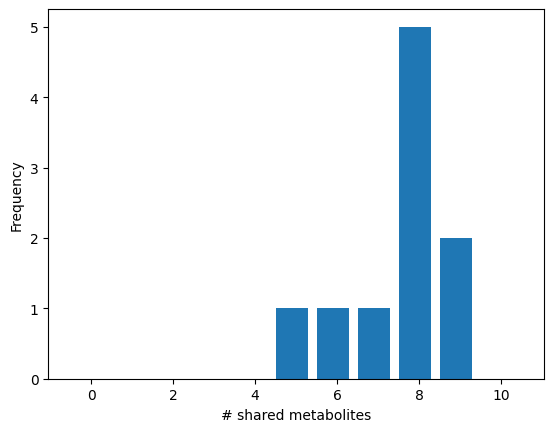

In [189]:
consumption = dataset4<-1
consumption = consumption.map(int)
network_cons = consumption.T.dot(consumption)
network_cons = network_cons.mask(np.tril(np.ones(network_cons.shape)).astype(np.bool)).stack() 

network_cons_bool = network_cons[network_cons>1]

network_cons_bool = (network_cons_bool>0).map(int)

data= networks.competition_centrality_metrics(network_cons_bool,SP_centrality=False)["degree (data)"]

ax = data.plot(kind="hist",bins=np.arange(12)-0.5, width=0.8)
ax.set_ylabel("Frequency")
ax.set_xlabel("# shared metabolites")

In [193]:
f"{network_cons_bool.size/(12*(12-1)/2) *100}% of all possible links "

'57.57575757575758% of all possible links '

In [191]:
net = networks.competition_network(network_cons,closeness_centrality_met=False,cutoff=1)
net.show("network_file.html")

network_file.html


## Stricter threshold

Text(0.5, 0, '# shared metabolites')

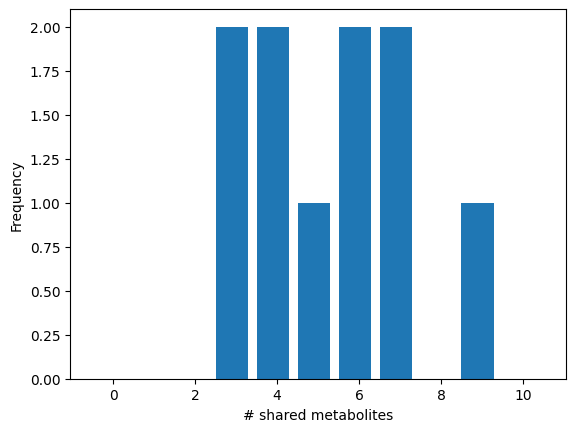

In [186]:
consumption = dataset4<-2
consumption = consumption.map(int)
network_cons = consumption.T.dot(consumption)
network_cons = network_cons.mask(np.tril(np.ones(network_cons.shape)).astype(np.bool)).stack() 

network_cons_bool = network_cons[network_cons>1]

network_cons_bool = (network_cons_bool>0).map(int)

data= networks.competition_centrality_metrics(network_cons_bool,SP_centrality=False)["degree (data)"]

ax = data.plot(kind="hist",bins=np.arange(12)-0.5, width=0.8)
ax.set_ylabel("Frequency")
ax.set_xlabel("# shared metabolites")

In [187]:
network_cons_bool.size/(12*(12-1)/2)

0.4090909090909091

In [188]:
net = networks.competition_network(network_cons,closeness_centrality_met=False,cutoff=1)
net.show("network_file.html")

network_file.html


### Cooperation (dataset4<=-1)

In [202]:
consumption = dataset4<=-3
consumption = consumption.map(int)
consumption.name="consumption"

production = dataset4>=1
production = production.map(int)
production.name="production"
network_cons = production.T.dot(consumption)


network_cons = network_cons.stack()
network_cons= network_cons[network_cons>0]

**Degree distribution (without edge weight)**

<Axes: ylabel='Frequency'>

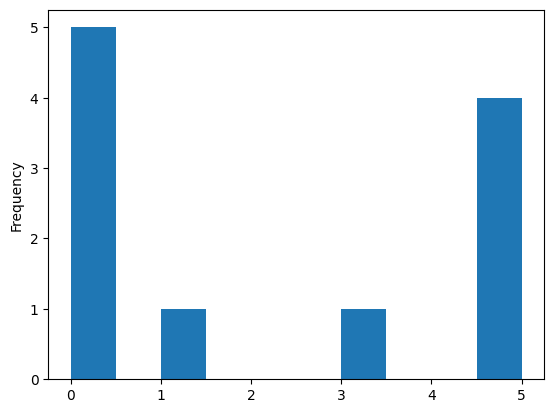

In [203]:
network_cons_bool = (network_cons>0).map(int)

networks.cooperation_centrality_metrics(network_cons_bool,SP_centrality=False,degree_type="in")["degree (data)"].plot(kind="hist")

<Axes: ylabel='Frequency'>

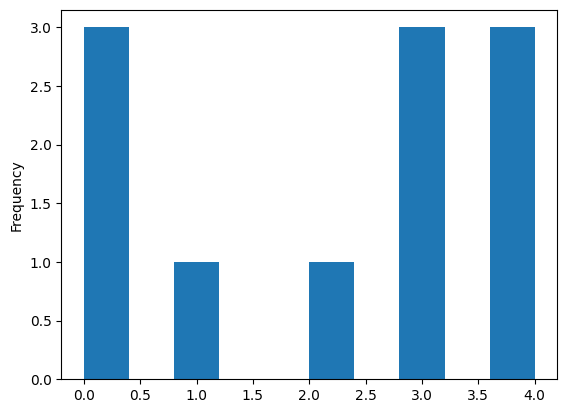

In [204]:
network_cons_bool = (network_cons>0).map(int)

networks.cooperation_centrality_metrics(network_cons_bool,SP_centrality=False,degree_type="out")["degree (data)"].plot(kind="hist")

In [205]:
network_cons.min()

np.int64(1)

In [206]:
network_cons.max()

np.int64(3)

In [207]:
net = networks.cooperation_network(network_cons,closeness_centrality_met=False,cutoff=0)
net.show("network_file.html")

network_file.html


In [209]:
network_cons.size/(12*11)*100

18.181818181818183